# DBSCAN: guia passo a passo

**O que você vai aprender:** entender o problema, conhecer os dados, separar uma parte para conferir o resultado, preparar as colunas, treinar, comparar e interpretar.

Leia uma célula por vez. Antes de executar, tente responder: “o que entra aqui e o que sai?”. Os dados deste exemplo são didáticos; os números não são uma regra para todos os exercícios.

**Palavras úteis:** *atributos* são as colunas usadas para prever; *alvo* é a resposta que queremos descobrir; *treino* é a parte usada para aprender; *teste* é a parte guardada para conferir o resultado no fim.

## Antes do código: entendendo o caminho

**1. Qual é a pergunta?** Em regressão queremos prever um número, como gasto. Em classificação queremos escolher uma categoria, como “houve evento” ou “não houve”. Em agrupamento buscamos semelhanças sem uma resposta pronta. Diga isso em uma frase antes de escolher o algoritmo.

**2. O que são X e y?** `X` é uma tabela: linhas são casos, colunas são informações conhecidas no momento da previsão. `y` é a resposta de cada linha. Se uma coluna só aparece depois do resultado, ela não pode entrar em `X`: seria como olhar o gabarito.

**3. Por que guardar um teste?** O algoritmo pode se sair bem nos exemplos que já viu e falhar nos novos. Guardamos alguns casos e evitamos usá-los para escolher colunas, parâmetros ou modelos. A validação cruzada usa apenas o treino para comparar opções.

**4. O que faz o pipeline?** Ele guarda a receita completa: preencher dados ausentes, converter categorias, ajustar escalas quando necessário e treinar o modelo. Quando essa receita é testada em uma parte da validação, seus ajustes são aprendidos apenas na parte de treino daquela rodada.

**5. Como ler uma métrica?** Uma métrica resume um aspecto do erro. Ela não responde sozinha se o modelo é útil. Compare com o baseline, veja os tipos de erro e pense no custo real de errar. Uma diferença pequena entre médias de validação pode mudar em outra amostra.


## Fundamentos estatísticos para interpretar o resultado

**População e amostra.** População é o conjunto de casos sobre o qual gostaríamos de concluir. Amostra são as linhas disponíveis. Um teste em 140 pessoas descreve o desempenho nessas pessoas; é uma estimativa do que pode ocorrer em outras semelhantes, não uma garantia. Se o modo de coletar os dados favorece um grupo, uma divisão aleatória não corrige esse problema.

**Média, mediana e dispersão.** A média soma os valores e divide pela quantidade; é sensível a extremos. A mediana é o valor central depois de ordenar; resiste mais a extremos. O desvio padrão descreve o espalhamento em torno da média. Antes de tratar um valor extremo, investigue se é erro de registro ou um caso real importante.

**Correlação.** Resume associação linear entre duas variáveis. Perto de 1 indica que tendem a subir juntas; perto de -1, que uma tende a cair quando a outra sobe; perto de 0 não descarta relações curvas. Correlação não demonstra causa. Também pode mudar quando analisamos subgrupos.

**Incerteza e validação.** A média dos folds da validação cruzada resume vários treinos; o desvio entre folds mostra quanto os resultados variaram nessas divisões. Ele não é um intervalo de confiança. Ajustar muitos parâmetros e escolher o maior score pode produzir otimismo: por isso mantemos o teste separado até o final. Em dados temporais, a validação precisa respeitar a ordem do tempo.


## Estatística e geometria em dados sem rótulo

**Distância e escala.** Agrupamentos dependem de quão próximos os pontos parecem. Se uma coluna varia de 0 a 1 e outra de 0 a 10000, a segunda pode dominar a distância; a padronização muda a geometria. Isso é uma escolha de análise, não uma verdade neutra.

**Silhouette.** Para um ponto, comparamos a distância média até seu próprio grupo com a distância média até o grupo vizinho mais próximo. O índice vai de -1 a 1: perto de 1 indica boa separação; perto de 0, fronteira; negativo pode indicar associação estranha. A média resume a amostra, mas favorece certas formas de grupo. No DBSCAN, pontos marcados como ruído são excluídos do cálculo do notebook; por isso também mostramos a cobertura.

**PCA e variância.** Variância mede espalhamento. O PCA procura direções que preservem muito desse espalhamento; “95% de variância explicada” quer dizer que os componentes retêm 95% da variação medida nesse treino, não que acertam 95% das previsões. É preciso avaliar a tarefa final separadamente.


## Ideia do algoritmo, sem fórmula

DBSCAN procura regiões com muitos pontos próximos. Pontos isolados podem receber o rótulo -1, chamado ruído.

`eps` define o raio de vizinhança; `min_samples` define quantos vizinhos justificam uma região densa. Raios pequenos criam muito ruído; grandes podem juntar grupos.

A proporção de pontos aproveitados importa. Um silhouette alto calculado sobre pouquíssimos pontos não garante um agrupamento útil.

**Experimento mental:** se uma coluna passar a ter valores dez vezes maiores, o que pode mudar? Se o treino tiver poucos exemplos, o que pode acontecer? Depois de executar, compare suas respostas com os resultados.

## 1. Objetivo e dados
Explorar segmentos em uma base **sintética** bidimensional. Não existe alvo: silhouette mede separação geométrica, não utilidade comercial nem acurácia. Este é um estudo exploratório no conjunto observado, sem alegação de generalização preditiva.

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

## Guia das funções e métodos usados neste notebook

As explicações também aparecem ao lado das células que usam cada função. Use este índice quando quiser rever uma ferramenta.

**`pd.DataFrame`** — Cria uma tabela com linhas e colunas. Aqui organiza as informações de entrada; não treina nada.

**`describe`** — Calcula resumos como quantidade, média, desvio padrão, mínimo, quartis e máximo. Serve para procurar escalas e valores estranhos.

**`isna`** — Marca valores ausentes. Com `mean`, produz a fração ausente em cada coluna, porque verdadeiro conta como 1.

**`groupby`** — Separa linhas por grupo para calcular resumos de cada segmento.

**`agg`** — Escolhe os resumos a calcular por grupo, como média e quantidade.

**`StandardScaler`** — Aprende média e desvio padrão no treino e transforma as colunas numéricas para escalas comparáveis. É importante para distâncias, SVM e modelos com regularização.

**`fit`** — Ajusta o modelo aos dados de treino. Em transformadores, aprende estatísticas como mediana e escala; em estimadores, aprende regras ou parâmetros.

**`predict`** — Gera uma resposta para cada linha. Em regressão, um número; em classificação, uma classe.

**`fit_transform`** — Aprende os parâmetros da transformação no conjunto fornecido e já devolve os dados transformados. Na validação, deve acontecer dentro do pipeline.

**`fit_predict`** — Ajusta um agrupador e devolve o rótulo do grupo de cada linha. Os números dos grupos são nomes arbitrários.

**`silhouette_score`** — Compara a proximidade de cada ponto com seu grupo e com o grupo vizinho. Valores maiores sugerem separação geométrica melhor, mas não garantem utilidade.

**`scatter`** — Desenha pontos em dois eixos. Neste guia, a cor indica o grupo ou a relação entre valor real e previsto.

**`KMeans`** — Agrupa pontos ao redor de `n_clusters` centros. `n_init` repete inicializações e fica com a melhor solução interna; `random_state` torna essas tentativas reproduzíveis.

**`DBSCAN`** — Encontra regiões densas. `eps` é o raio de vizinhança; `min_samples` é a quantidade mínima de pontos; -1 indica ruído.

**`AgglomerativeClustering`** — Une grupos sucessivamente. `n_clusters` define quantos restam no fim; `linkage="ward"` escolhe uniões com pequeno aumento da variação interna.

In [1]:
# Bibliotecas: trazemos ferramentas prontas para tabelas, gráficos e modelos.
import pandas as pd

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [2]:
# Bibliotecas: trazemos ferramentas prontas para tabelas, gráficos e modelos.
import matplotlib.pyplot as plt

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [3]:
from IPython.display import display

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [4]:
from sklearn.datasets import make_blobs

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [5]:
from sklearn.preprocessing import StandardScaler

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [6]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

**O que acontece nesta célula:** Carregamos ferramentas prontas. `import` traz uma biblioteca ou função para usar nas próximas células; ainda não treinamos nenhum modelo.

In [7]:
from sklearn.metrics import silhouette_score

**Funções e métodos desta célula**

`make_blobs` cria dados artificiais com grupos de pontos. `n_samples=350` cria 350 linhas; `centers=3` coloca os pontos ao redor de três centros; `cluster_std=1.0` controla o espalhamento dentro de cada grupo; `random_state=42` repete o mesmo sorteio. A função devolve duas coisas: as coordenadas dos pontos e os rótulos verdadeiros criados pelo gerador. Guardamos as coordenadas em `valores` e descartamos os rótulos com `_` para simular um problema sem respostas conhecidas. Os três centros pertencem apenas à construção do exemplo: o algoritmo de agrupamento não recebe esse número como gabarito.

In [8]:
# Ignoramos os rótulos do gerador: eles não entram na seleção.
valores, _ = make_blobs(n_samples=350, centers=3, cluster_std=1.0, random_state=42)

**Funções e métodos desta célula**

`pd.DataFrame` cria uma tabela. Cada coluna recebe uma lista de valores e cada posição na lista forma uma linha. Aqui a tabela contém os atributos usados no modelo.

In [9]:
dados = pd.DataFrame(valores, columns=["indicador_1", "indicador_2"])

**Funções e métodos desta célula**

`describe` calcula resumos como média, quartis e extremos, conforme o tipo de coluna.

In [10]:
display(dados.describe())

,indicador_1,indicador_2
count,350.000000,350.000000
mean,-1.595022,1.390429
std,4.907403,6.618991
min,-9.576514,-9.091245
25%,-6.245393,-6.179705
50%,-2.533302,1.915633
75%,3.911263,8.346998
max,6.829682,12.867018


**Funções e métodos desta célula**

`isna` marca os valores ausentes; ao tirar a média dessas marcas, obtemos a fração ausente.

In [11]:
display(dados.isna().sum())

indicador_1    0
indicador_2    0
dtype: int64

**O que acontece nesta célula:** Mostramos o resultado em texto. Leia o número junto da métrica e da base usada; um valor isolado não diz se o modelo é útil.

In [12]:
print("Duplicatas:", dados.duplicated().sum())

Duplicatas: 0


**Funções e métodos desta célula**

`scatter` desenha um ponto por linha. Cor pode representar grupo; eixos mostram as duas colunas escolhidas.

In [13]:
plt.scatter(dados.indicador_1, dados.indicador_2, s=15)

**O que acontece nesta célula:** Construímos um gráfico dos resultados. Confira os eixos, a legenda e se os pontos representam treino ou teste antes de interpretar.

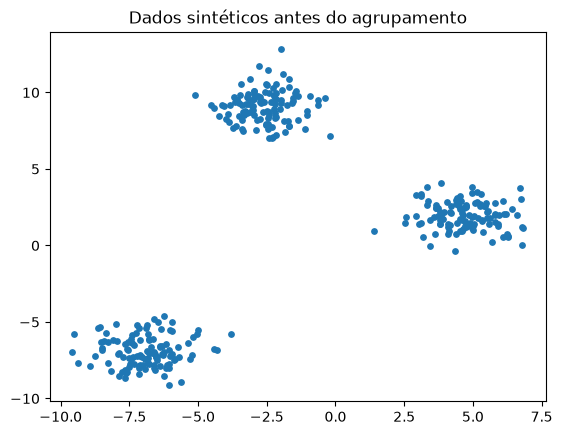

In [14]:
plt.title("Dados sintéticos antes do agrupamento"); plt.show()

**Funções e métodos desta célula**

`StandardScaler` aprende a média e o desvio padrão de cada coluna numérica no treino. Depois subtrai a média e divide pelo desvio padrão, permitindo comparar distâncias entre colunas em escalas diferentes.

In [15]:
# Aqui a base é completa. Em CSV real, investigue ausências e significado das distâncias.
escala = StandardScaler()

**Funções e métodos desta célula**

`fit_transform` aprende parâmetros de uma transformação e imediatamente devolve os dados transformados. Em padronização, aprende média e desvio padrão; em PCA, aprende direções de variação. Para avaliação supervisionada, deixe isso dentro do pipeline.

In [16]:
# Ajustamos a escala para uma coluna não dominar a distância.
Z = escala.fit_transform(dados)

## 2. Comparar configurações
Silhouette varia de -1 a 1; valores maiores indicam grupos mais separados na geometria escolhida. É indefinida com apenas um grupo ou um grupo por ponto. Para DBSCAN calculamos sem o ruído e exigimos cobertura mínima de 80%, regra didática que deve ser definida pelo problema. Comparar somente silhouette após descartar muitos pontos pode enganar.

**Funções e métodos desta célula**

`DBSCAN` cria um agrupador por densidade. `eps` determina até que distância dois pontos são vizinhos; `min_samples` é quantos pontos próximos justificam uma região densa. Ele pode marcar pontos isolados com -1. Valores adequados dependem da escala e da base.

In [17]:
# Cada entrada contém um modelo e as opções que queremos testar.
candidatos = {f"eps={eps};min={m}": DBSCAN(eps=eps, min_samples=m)
              for eps in [0.15, 0.25, 0.4, 0.6] for m in [5, 10]}

**O que acontece nesta célula:** Preparamos dois recipientes vazios: `linhas` receberá um resumo de cada teste; `rotulos` guardará o grupo atribuído a cada ponto em cada configuração.

In [18]:
linhas, rotulos = [], {}

**Funções e métodos desta célula**

`silhouette_score` recebe os pontos e o grupo atribuído a cada um. Para cada ponto, compara sua distância média ao próprio grupo com a distância ao grupo vizinho mais próximo; devolve a média dessas comparações. Perto de 1 sugere separação clara, perto de 0 indica fronteiras e valores negativos sugerem encaixe ruim. Precisa de pelo menos dois grupos e não comprova que os segmentos são úteis.

`fit_predict` ajusta o agrupador aos pontos e já devolve um número de grupo para cada linha. É diferente de `predict` de classificação: aqui não existiam rótulos corretos para aprender. No DBSCAN, -1 representa ruído.

In [19]:
# Experimentamos cada configuração de agrupamento.
for nome, modelo in candidatos.items():
# Cada linha recebe o número de um grupo; -1 pode indicar ruído.
    labels = modelo.fit_predict(Z)
    rotulos[nome] = labels
    validos = labels != -1
    grupos = len(set(labels[validos]))
    cobertura = validos.mean()
    score = float("nan")
    if 2 <= grupos < validos.sum():
        score = silhouette_score(Z[validos], labels[validos])
    linhas.append({"configuracao": nome, "grupos": grupos, "cobertura": cobertura,
                   "silhouette": score, "elegivel": cobertura >= 0.8 and pd.notna(score)})

**Funções e métodos desta célula**

`pd.DataFrame` cria uma tabela. Cada coluna recebe uma lista de valores e cada posição na lista forma uma linha. Aqui a tabela contém os atributos usados no modelo.

In [20]:
tabela = pd.DataFrame(linhas)

**O que acontece nesta célula:** Mostramos uma tabela para inspecionar o que foi calculado. Observe nomes das colunas, quantidade de linhas e valores inesperados.

In [21]:
display(tabela)

,configuracao,grupos,cobertura,silhouette,elegivel
0,eps=0.15;min=5,3,0.968571,0.853549,True
1,eps=0.15;min=10,3,0.942857,0.858575,True
2,eps=0.25;min=5,3,1.000000,0.845246,True
3,eps=0.25;min=10,3,1.000000,0.845246,True
4,eps=0.4;min=5,3,1.000000,0.845246,True
5,eps=0.4;min=10,3,1.000000,0.845246,True
6,eps=0.6;min=5,3,1.000000,0.845246,True
7,eps=0.6;min=10,3,1.000000,0.845246,True


**Funções e métodos desta célula**

`sort_values` ordena as linhas pela coluna indicada; `ascending=False` coloca os maiores valores primeiro.

In [22]:
elegiveis = tabela[tabela.elegivel].sort_values("silhouette", ascending=False)

**O que acontece nesta célula:** Se nenhuma opção cumprir os critérios, interrompemos com uma mensagem clara. Nesse caso, precisamos revisar escala, parâmetros e a pergunta antes de escolher um vencedor.

In [23]:
if elegiveis.empty:
    raise ValueError("Nenhuma configuração atende ao critério. Investigue os dados e reveja as hipóteses.")

**O que acontece nesta célula:** Pegamos a primeira linha da tabela ordenada. `iloc[0]` significa primeira linha; dela retiramos o nome da configuração escolhida.

In [24]:
nome = elegiveis.iloc[0].configuracao

**O que acontece nesta célula:** Recuperamos os grupos atribuídos por essa configuração. `labels` tem um número de grupo para cada linha dos dados.

In [25]:
labels = rotulos[nome]

**O que acontece nesta célula:** Mostramos o resultado em texto. Leia o número junto da métrica e da base usada; um valor isolado não diz se o modelo é útil.

In [26]:
print("Configuração exploratória selecionada:", nome)

Configuração exploratória selecionada: eps=0.15;min=10


**Funções e métodos desta célula**

`scatter` desenha um ponto por linha. Cor pode representar grupo; eixos mostram as duas colunas escolhidas.

In [27]:
plt.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="viridis", s=20)

**O que acontece nesta célula:** Construímos um gráfico dos resultados. Confira os eixos, a legenda e se os pontos representam treino ou teste antes de interpretar.

In [28]:
plt.title(nome + " — -1 representa ruído quando presente")

**O que acontece nesta célula:** Construímos um gráfico dos resultados. Confira os eixos, a legenda e se os pontos representam treino ou teste antes de interpretar.

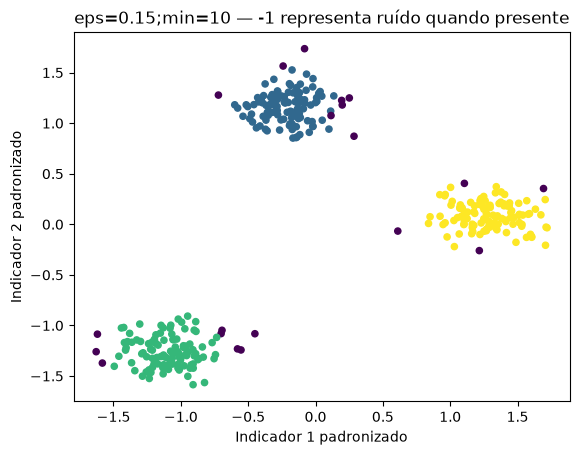

In [29]:
plt.xlabel("Indicador 1 padronizado"); plt.ylabel("Indicador 2 padronizado"); plt.show()

**Funções e métodos desta célula**

`groupby` separa as linhas por grupo para calcular um perfil de cada segmento.

`agg` escolhe quais resumos calcular após separar os grupos, como média e contagem.

In [30]:
# O perfil nas unidades originais ajuda a interpretar cada segmento.
perfil = dados.assign(grupo=labels).groupby("grupo").agg(["mean", "count"])

**O que acontece nesta célula:** Mostramos uma tabela para inspecionar o que foi calculado. Observe nomes das colunas, quantidade de linhas e valores inesperados.

In [31]:
display(perfil)

indicador_1       indicador_2      
             mean count        mean count
grupo                                    
-1      -2.374815    20    1.789971    20
 0      -2.675169   109    9.031192   109
 1      -6.969712   108   -6.954527   108
 2       4.721779   113    1.925128   113

## 3. Conclusão e próximos exercícios
Encontra regiões densas e marca ruído com -1. Não exige k, mas depende muito de eps, min_samples e escala. Não possui predict nativo para novos pontos.

A configuração selecionada maximiza o critério entre as opções elegíveis nesta amostra. Os números dos grupos são identificadores arbitrários, sem ordem ou significado prévio. Examine tamanhos, estabilidade ao reamostrar e interpretação dos perfis antes de dar nomes aos segmentos. Silhouette favorece certas formas de grupo: não decide tudo.

**Pratique:** varie a escala; acrescente outliers; compare outras sementes e amostras; use `make_moons` para observar grupos não convexos; explique por que mudar a geometria pode mudar a escolha. Para novos clientes, K-Means permite `predict` após aplicar a mesma escala; DBSCAN e hierárquico exigem uma estratégia adicional, não apenas chamar `predict`.